# ДОМАШНЯЯ РАБОТА 9: Полный цикл ML-проекта (Telco Churn)


In [1]:
!pip -q install lightgbm shap onnxmltools onnxruntime kagglehub

In [2]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, precision_recall_curve, auc, brier_score_loss

import lightgbm as lgb
import shap

import warnings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

### 1. Загрузка данных
Используем `kagglehub` для автоматической загрузки.

In [3]:
try:
    import kagglehub
    path = kagglehub.dataset_download("blastchar/telco-customer-churn")
    file_path = os.path.join(path, 'WA_Fn-UseC_-Telco-Customer-Churn.csv')
    df = pd.read_csv(file_path)
except Exception as e:
    print("Ошибка автоматической загрузки. Загрузите файл CSV вручную через меню слева.")
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(list(uploaded.keys())[0])

print(f"Датасет загружен: {df.shape[0]} строк, {df.shape[1]} столбцов")
display(df.head(2))

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Датасет загружен: 7043 строк, 21 столбцов


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.950,1889.5,No


### 2. Предобработка данных

In [4]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.dropna(inplace=True)

X = df.drop(['customerID', 'Churn'], axis=1, errors='ignore')
y = (df['Churn'] == 'Yes').astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ])

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)
print(f"Размерность после OHE: Train {X_train_prep.shape}, Test {X_test_prep.shape}")

Размерность после OHE: Train (5625, 45), Test (1407, 45)


### 3. Baseline: Логистическая регрессия

In [5]:
baseline = LogisticRegression(max_iter=1000, random_state=42)
baseline.fit(X_train_prep, y_train)

y_proba_base = baseline.predict_proba(X_test_prep)[:, 1]
prec_base, rec_base, _ = precision_recall_curve(y_test, y_proba_base)
pr_auc_base = auc(rec_base, prec_base)

print(f"Baseline Logistic Regression (PR-AUC: {pr_auc_base:.3f}, Brier: {brier_score_loss(y_test, y_proba_base):.3f})")

Baseline Logistic Regression (PR-AUC: 0.621, Brier: 0.140)


### 4. LightGBM с GridSearch

In [6]:
lgb_model = lgb.LGBMClassifier(random_state=42, verbose=-1)
param_grid = {'n_estimators': [50, 100], 'max_depth': [3, 5], 'learning_rate': [0.05, 0.1]}

grid = GridSearchCV(lgb_model, param_grid, cv=3, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train_prep, y_train)

best_lgb = grid.best_estimator_
y_proba_lgb = best_lgb.predict_proba(X_test_prep)[:, 1]
prec_lgb, rec_lgb, _ = precision_recall_curve(y_test, y_proba_lgb)
pr_auc_lgb = auc(rec_lgb, prec_lgb)

print(f"LightGBM (Best Params: {grid.best_params_})")
print(f"PR-AUC: {pr_auc_lgb:.3f}")
print(f"Brier Score: {brier_score_loss(y_test, y_proba_lgb):.3f}")

LightGBM (Best Params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100})
PR-AUC: 0.655
Brier Score: 0.138


### 5. Бизнес-порог (Стоимость ошибок)

In [7]:
thresholds = np.linspace(0.05, 0.95, 50)
costs = []

for t in thresholds:
    y_pred_t = (y_proba_lgb >= t).astype(int)
    fn = ((y_test == 1) & (y_pred_t == 0)).sum()
    fp = ((y_test == 0) & (y_pred_t == 1)).sum()
    costs.append(fn * 5000 + fp * 200)

best_t = thresholds[np.argmin(costs)]
y_pred_business = (y_proba_lgb >= best_t).astype(int)

print(f"Оптимальный порог: {best_t:.2f}")
print(classification_report(y_test, y_pred_business, target_names=['No Churn', 'Churn']))

Оптимальный порог: 0.05
              precision    recall  f1-score   support

    No Churn       0.98      0.36      0.52      1033
       Churn       0.36      0.98      0.52       374

    accuracy                           0.52      1407
   macro avg       0.67      0.67      0.52      1407
weighted avg       0.81      0.52      0.52      1407



### 6. SHAP-интерпретация


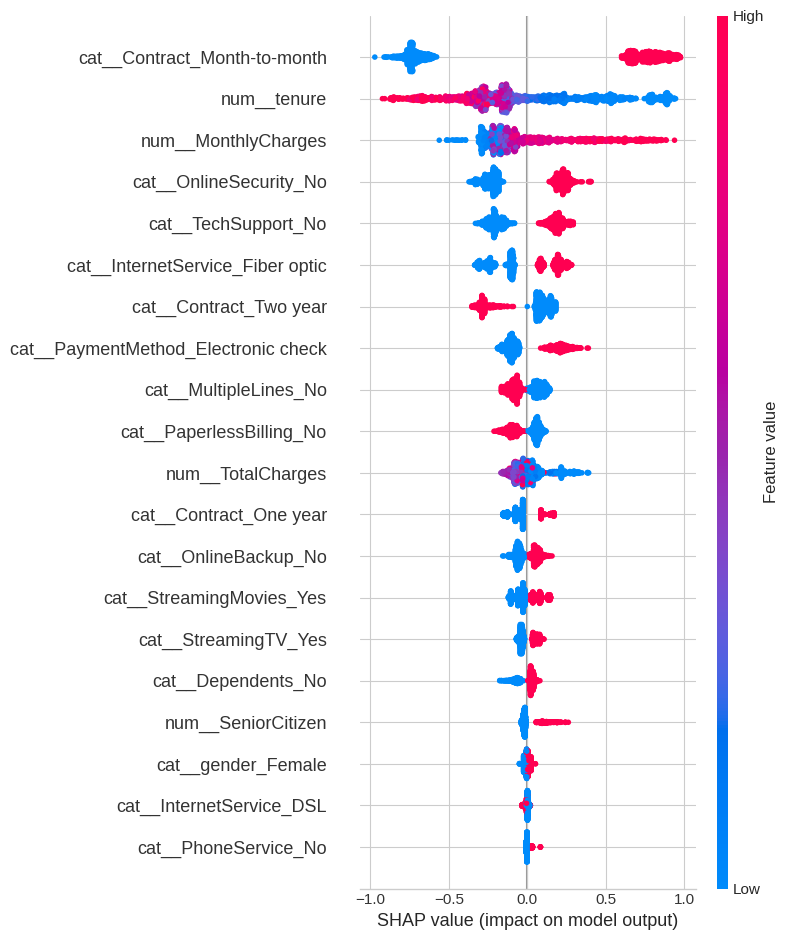

In [8]:
explainer = shap.TreeExplainer(best_lgb)
shap_values = explainer.shap_values(X_test_prep)

if isinstance(shap_values, list):
    shap_values_to_plot = shap_values[1]
else:
    shap_values_to_plot = shap_values[:, :, 1] if len(shap_values.shape) == 3 else shap_values

shap.summary_plot(
    shap_values_to_plot,
    X_test_prep,
    feature_names=preprocessor.get_feature_names_out(),
    show=True
)

### 7. Экспорт в ONNX и бенчмарк

In [9]:
from onnxmltools.convert import convert_lightgbm
from onnxmltools.convert.common.data_types import FloatTensorType
import onnxruntime as ort

initial_type = [('float_input', FloatTensorType([None, X_train_prep.shape[1]]))]
onnx_model = convert_lightgbm(best_lgb, initial_types=initial_type, zipmap=False)

with open("churn_model.onnx", "wb") as f:
    f.write(onnx_model.SerializeToString())
print("Модель сохранена в churn_model.onnx")

session = ort.InferenceSession("churn_model.onnx")
input_name = session.get_inputs()[0].name

_ = session.run(None, {input_name: X_test_prep[:1].astype(np.float32)})

n_iter = 100
start = time.time()
for _ in range(n_iter):
    _ = session.run(None, {input_name: X_test_prep[:1].astype(np.float32)})
onnx_time = (time.time() - start) / n_iter * 1000

start = time.time()
for _ in range(n_iter):
    _ = best_lgb.predict_proba(X_test_prep[:1])
sklearn_time = (time.time() - start) / n_iter * 1000

print(f"\nИнференс 1 объекта (среднее за {n_iter} итераций):")
print(f"  ONNX Runtime: {onnx_time:.3f} мс")
print(f"  sklearn LGBM: {sklearn_time:.3f} мс")
print(f"  Ускорение:    {sklearn_time / onnx_time:.1f}x")

Модель сохранена в churn_model.onnx

Инференс 1 объекта (среднее за 100 итераций):
  ONNX Runtime: 0.037 мс
  sklearn LGBM: 1.429 мс
  Ускорение:    38.2x


### 8. Мини-сервис на FastAPI

In [13]:
fastapi_code = '''
from fastapi import FastAPI
from pydantic import BaseModel
import numpy as np
import onnxruntime as ort

app = FastAPI(title="Churn Prediction API")
session = ort.InferenceSession("churn_model.onnx")
input_name = session.get_inputs()[0].name

class Features(BaseModel):
    features: list[float]

@app.post("/predict")
def predict(req: Features):
    arr = np.array([req.features], dtype=np.float32)
    raw_output = session.run(None, {input_name: arr})[0]

    # Универсальная обработка формата ответа ONNX
    if len(np.array(raw_output).shape) > 1 and np.array(raw_output).shape[1] > 1:
        proba = raw_output[0][1]
    else:
        proba = raw_output[0]

    return {"churn_probability": float(proba), "churn": bool(proba > 0.5)}
'''

with open("app.py", "w") as f:
    f.write(fastapi_code)
print("Файл app.py создан. Запуск: uvicorn app:app --reload")
print("Пример запроса: curl -X POST http://127.0.0.1:8000/predict -H 'Content-Type: application/json' -d '{\"features\": [1.0, 2.0, 3.0]}'")

test_features = X_test_prep[0].astype(np.float32).tolist()
raw_output = session.run(None, {input_name: np.array([test_features], dtype=np.float32)})[0]

if len(np.array(raw_output).shape) > 1 and np.array(raw_output).shape[1] > 1:
    proba_onnx = raw_output[0][1]
else:
    proba_onnx = raw_output[0]

print(f"\nТестовый прогноз (ONNX): вероятность оттока = {float(proba_onnx):.3f}")

Файл app.py создан. Запуск: uvicorn app:app --reload
Пример запроса: curl -X POST http://127.0.0.1:8000/predict -H 'Content-Type: application/json' -d '{"features": [1.0, 2.0, 3.0]}'

Тестовый прогноз (ONNX): вероятность оттока = 0.000


## Итоги и рекомендации
1. **Бизнес-порог ≠ ML-порог.** Стоимость FP и FN нужно всегда обсуждать с заказчиком.
2. **Мониторинг дрейфа обязателен.** PSI > 0.2 — сигнал к переобучению. Evidently AI автоматизирует отчёты.
3. **ONNX ускоряет инференс** и позволяет запускать модель на CPU без Python-зависимостей.
4. **SHAP объясняет решения** — критически важно для кредитного скоринга и медицины (регуляторные требования).